In [15]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import numpy as np
import pandas as pd
import matplotlib
import sklearn
import torch
import keras

print("NumPy :", np.__version__)
print("Pandas :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)
print("Scikit-learn :", sklearn.__version__)
print("PyTorch :", torch.__version__)
print("Keras :", keras.__version__)
print("Backend Keras :", keras.backend.backend())

NumPy : 2.4.2
Pandas : 3.0.1
Matplotlib : 3.11.0
Scikit-learn : 1.9.0
PyTorch : 2.14.1+cpu
Keras : 3.16.0.dev2026101704
Backend Keras : torch


In [16]:
# Phase 1 : Importation et exploration des données
# Question 1 : Chargement des fichiers CSV

import pandas as pd

train = pd.read_csv("credit_train.csv", sep=";")
val = pd.read_csv("credit_val.csv", sep=";")
test = pd.read_csv("credit_test.csv", sep=";")



 Nous chargeons les trois fichiers CSV. Train sert à apprendre, Validation à comparer les modèles et Test à les évaluer à la fin.

In [17]:
# Phase 1 - Question 2 : Afficher les premières lignes

print("Données d'entraînement :")
display(train.head())

print("Données de validation :")
display(val.head())

print("Données de test :")
display(test.head())


Données d'entraînement :


,revenu_mensuel,taux_endettement,retards_paiement,anciennete_emploi,defaut_paiement
0,-0.981125,0.539607,0.363548,0.421519,0
1,-0.687663,2.781215,3.654281,0.645902,1
2,-0.625569,0.005611,-0.733363,-0.027246,0
3,1.477623,-1.367521,0.363548,-1.149160,0
4,1.193693,0.181654,1.460459,-0.476012,0


Données de validation :


,revenu_mensuel,taux_endettement,retards_paiement,anciennete_emploi,defaut_paiement
0,-0.272589,-1.267763,-0.733363,-0.251629,0
1,-0.670400,0.967977,-0.733363,0.645902,0
2,-0.828854,-0.909810,-0.733363,-1.149160,0
3,-0.183443,-0.252585,-0.733363,0.645902,0
4,-0.229047,-0.317134,-0.733363,-0.476012,0


Données de test :


,revenu_mensuel,taux_endettement,retards_paiement,anciennete_emploi,defaut_paiement
0,-0.147887,-0.164563,-0.733363,-0.924777,0
1,0.038909,-1.320576,-0.733363,-0.251629,0
2,-0.290883,-1.297104,-0.733363,-0.924777,0
3,0.717815,-0.903942,-0.733363,0.197136,0
4,-0.909241,0.915164,0.363548,0.421519,0


Nous affichons les cinq premières lignes de chaque fichier pour découvrir les variables et vérifier la structure des données.

In [18]:
# Phase 1 - Question 3 : Dimensions des datasets

print("Dimensions Train :", train.shape)
print("Dimensions Validation :", val.shape)
print("Dimensions Test :", test.shape)

Dimensions Train : (2100, 5)
Dimensions Validation : (450, 5)
Dimensions Test : (450, 5)


Nous vérifions la taille des jeux de données : 2 100 lignes pour Train, 450 pour Validation et 450 pour Test.

In [19]:
# Phase 1 - Question 4 : Vérification des valeurs manquantes

print("Valeurs manquantes Train :")
print(train.isnull().sum())

print("\nValeurs manquantes Validation :")
print(val.isnull().sum())

print("\nValeurs manquantes Test :")
print(test.isnull().sum())

Valeurs manquantes Train :
revenu_mensuel       0
taux_endettement     0
retards_paiement     0
anciennete_emploi    0
defaut_paiement      0
dtype: int64

Valeurs manquantes Validation :
revenu_mensuel       0
taux_endettement     0
retards_paiement     0
anciennete_emploi    0
defaut_paiement      0
dtype: int64

Valeurs manquantes Test :
revenu_mensuel       0
taux_endettement     0
retards_paiement     0
anciennete_emploi    0
defaut_paiement      0
dtype: int64


Nous cherchons les valeurs manquantes. Le résultat est 0 dans toutes les colonnes : aucune valeur ne manque.

In [20]:
# Phase 1 - Question 5 : Séparation des variables

X_train = train.drop("defaut_paiement", axis=1)
y_train = train["defaut_paiement"]

X_val = val.drop("defaut_paiement", axis=1)
y_val = val["defaut_paiement"]

X_test = test.drop("defaut_paiement", axis=1)
y_test = test["defaut_paiement"]

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_val :", X_val.shape)
print("y_val :", y_val.shape)

print("X_test :", X_test.shape)
print("y_test :", y_test.shape)

X_train : (2100, 4)
y_train : (2100,)
X_val : (450, 4)
y_val : (450,)
X_test : (450, 4)
y_test : (450,)


Nous séparons les 4 variables explicatives (X) de la variable à prédire, defaut_paiement (y), pour les trois jeux de données.

Dans cette phase, nous avons chargé les trois datasets avec Pandas. Ensuite, nous avons exploré les données, vérifié leurs dimensions et l'absence de valeurs manquantes. Enfin, nous avons séparé les variables explicatives X de la variable cible y pour préparer l'entraînement du modèle MLP.

In [ ]:
 # Phase 2 - Question 1 : Construction du MLP
X_train = train.drop(columns=["defaut_paiement"])
y_train = train["defaut_paiement"]

X_val = val.drop(columns=["defaut_paiement"])
y_val = val["defaut_paiement"]

X_test = test.drop(columns=["defaut_paiement"]) 
y_test = test["defaut_paiement"]

Cette cellule reprend la séparation entre les données d'entrée X et la cible y. Cette séparation était déjà effectuée en Phase 1.

In [22]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
from keras.models import Sequential
from keras.layers import Input, Dense

keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(4,)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

print("Modèle MLP construit avec succès.")

Modèle MLP construit avec succès.


Nous construisons un réseau MLP avec 4 entrées, deux couches cachées de 16 et 8 neurones, puis une sortie Sigmoid pour estimer le risque de défaut.

In [23]:
# Phase 2 - Question 3 : Résumé du modèle

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

model.summary() montre les couches du réseau et le nombre de paramètres de chacune. Le modèle contient 225 paramètres entraînables.

In [24]:
# Phase 2 - Question 4 : Nombre total de paramètres

print("Nombre total de paramètres :", model.count_params())

Nombre total de paramètres : 225


count_params() vérifie le total des paramètres du modèle. Le résultat est 225, comme dans le résumé précédent

### Phase 2 — Question 5 : Fonctions d'activation

**ReLU :** Nous utilisons ReLU dans les couches cachées, car elle introduit la non-linéarité et permet au réseau d'apprendre des relations complexes.

**Sigmoid :** Nous utilisons Sigmoid dans la couche de sortie, car elle produit une valeur entre 0 et 1, interprétée comme une probabilité de défaut de paiement.

### Phase 2 — Question 6 : Calcul manuel des paramètres

Le nombre de paramètres d'une couche Dense se calcule par :

**Paramètres = (Nombre d'entrées × Nombre de neurones) + Nombre de biais**

- **Couche 1 (4 → 16) :** (4 × 16) + 16 = 80 paramètres.
- **Couche 2 (16 → 8) :** (16 × 8) + 8 = 136 paramètres.
- **Couche 3 (8 → 1) :** (8 × 1) + 1 = 9 paramètres.

**Total = 80 + 136 + 9 = 225 paramètres.**

Ce résultat correspond au nombre de paramètres affiché par `model.summary()`.

In [25]:
# Phase 3 - Question 1 : Compilation du modèle

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)



Nous préparons le modèle à l'entraînement : Adam ajuste les poids, Binary Cross-Entropy mesure l'erreur et Accuracy mesure les bonnes prédictions.

### Phase 3 — Question 2 : Rôle de l'optimiseur Adam

Adam est un algorithme d'optimisation utilisé pour entraîner le réseau de neurones.

Il ajuste les poids et les biais à partir des gradients afin de minimiser la fonction de perte (Loss).

Il adapte automatiquement le taux d'apprentissage pour chaque paramètre, ce qui facilite l'entraînement du modèle.

### Phase 3 — Question 3 : Binary Cross-Entropy

La Binary Cross-Entropy est une fonction de perte adaptée à la classification binaire (0 ou 1).

Elle mesure l'erreur entre la vraie classe et la probabilité prédite par le modèle.

Elle pénalise fortement les prédictions incorrectes et permet au modèle d'améliorer son apprentissage.

### Phase 3 — Question 4 : Différence entre Loss et Accuracy

**Loss :** Elle mesure l'erreur entre les vraies valeurs et les probabilités prédites par le modèle. L'objectif est de la minimiser pendant l'entraînement.

**Accuracy :** Elle mesure le pourcentage de prédictions correctes. Plus elle est élevée, meilleures sont les prédictions en termes de classes correctes.

**Différence :** La Loss sert à guider l'apprentissage du modèle, tandis que l'Accuracy sert à évaluer ses performances.

### Phase 3 — Question 5 : Importance de la compilation

La compilation est nécessaire avant l'entraînement, car elle permet de définir l'optimiseur, la fonction de perte et les métriques d'évaluation.

Elle prépare le modèle à l'apprentissage en précisant comment minimiser l'erreur et mesurer ses performances.

Sans compilation, le modèle ne peut pas être entraîné avec `model.fit()` dans cette configuration.

In [26]:
# Phase 4 - Question 1 : Entraînement du modèle

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8400 - loss: 0.5255 - val_accuracy: 0.8467 - val_loss: 0.4379
Epoch 2/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8462 - loss: 0.4078 - val_accuracy: 0.8467 - val_loss: 0.3686
Epoch 3/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8467 - loss: 0.3689 - val_accuracy: 0.8467 - val_loss: 0.3488
Epoch 4/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8486 - loss: 0.3551 - val_accuracy: 0.8489 - val_loss: 0.3416
Epoch 5/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8510 - loss: 0.3491 - val_accuracy: 0.8422 - val_loss: 0.3389
Epoch 6/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8533 - loss: 0.3461 - val_accuracy: 0.8644 - val_loss: 0.3372
Epoch 7/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8567 - loss: 0.3440 - val_accuracy: 0.8578 - val_loss: 0.3362
Epoch 8/30
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8557 - loss: 0.3425 - val_accuracy: 0.8533 - val_loss:

Nous entraînons le réseau pendant 30 époques, par lots de 32 observations. À chaque époque, nous suivons les résultats sur Train et Validation.

### Phase 4 — Question 2 : Epochs et Batch Size

**Epoch :** Une époque correspond à un passage complet sur toutes les données d'entraînement. Ici, le modèle effectue 30 époques.

**Batch Size :** C'est le nombre d'observations traitées avant chaque mise à jour des paramètres du modèle. Ici, chaque batch contient au maximum 32 observations.

Avec 2 100 observations et un batch size de 32, nous obtenons 66 batches par époque.

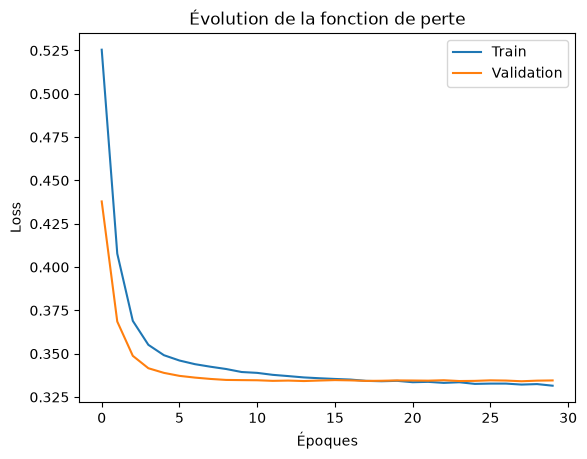

In [27]:
# Phase 4 - Question 3 : Courbes de Loss

import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Évolution de la fonction de perte")

plt.legend()
plt.show()

Ce graphique compare la Loss de Train et de Validation. La diminution puis la stabilisation des courbes indiquent que l'apprentissage progresse.

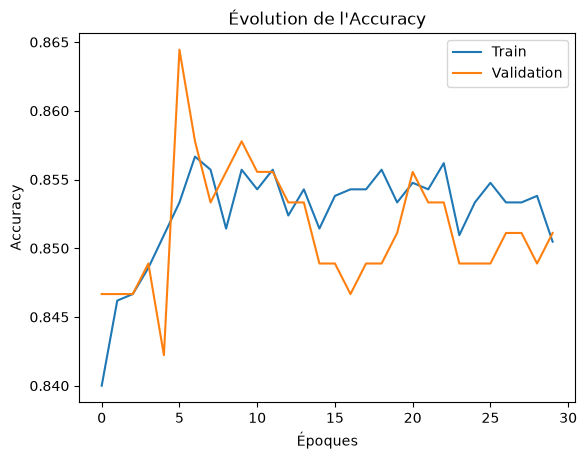

In [28]:
# Phase 4 - Question 4 : Courbes d'Accuracy

import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.title("Évolution de l'Accuracy")

plt.legend()
plt.show()

Ce graphique montre l'évolution de l'Accuracy pendant l'entraînement. Les résultats de Train et Validation restent proches, autour de 85 %.

### Phase 4 — Question 4 : Interprétation des courbes d'Accuracy

Les courbes montrent que l'Accuracy augmente au début de l'entraînement, puis se stabilise autour de 85 %.

Les performances sur les données d'entraînement et de validation restent proches, ce qui indique une généralisation satisfaisante.

Nous n'observons pas de signe évident de surapprentissage sur les 30 époques.

### Phase 4 — Question 5 : Analyse de la convergence et du surapprentissage

**Convergence :** Le modèle semble converger, car les courbes de perte diminuent progressivement puis se stabilisent autour de 0,33.

**Surapprentissage :** Nous n'observons pas de surapprentissage évident, car les courbes d'entraînement et de validation restent proches.

**Conclusion :** Le modèle présente un apprentissage stable et une généralisation satisfaisante sur les données de validation.

In [29]:
# Phase 4 - Question 6 : Nouveau modèle avec 50 époques

keras.utils.set_random_seed(42)

model_50 = Sequential([
    Input(shape=(4,)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model_50.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_50 = model_50.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/50


66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8400 - loss: 0.5255 - val_accuracy: 0.8467 - val_loss: 0.4379
Epoch 2/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8462 - loss: 0.4078 - val_accuracy: 0.8467 - val_loss: 0.3686
Epoch 3/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8467 - loss: 0.3689 - val_accuracy: 0.8467 - val_loss: 0.3488
Epoch 4/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8486 - loss: 0.3551 - val_accuracy: 0.8489 - val_loss: 0.3416
Epoch 5/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8510 - loss: 0.3491 - val_accuracy: 0.8422 - val_loss: 0.3389
Epoch 6/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8533 - loss: 0.3461 - val_accuracy: 0.8644 - val_loss: 0.3372
Epoch 7/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8567 - loss: 0.3440 - val_accuracy: 0.8578 - val_loss: 0.3362
Epoch 8/50
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8557 - loss: 0.3425 - val_accuracy: 0.8533 - val_loss: 0.3354
Epo

Nous créons un nouveau modèle avec la même architecture, mais 50 époques au lieu de 30, pour vérifier si un entraînement plus long améliore les résultats.

### Phase 4 — Question 6 : Comparaison entre 30 et 50 époques

Après avoir entraîné un nouveau modèle pendant 50 époques, nous avons comparé les résultats avec ceux du modèle entraîné pendant 30 époques.

| Métrique | 30 époques | 50 époques |
|---|---|---|
| Accuracy Train | 85,05 % | 85,43 % |
| Accuracy Validation | 85,11 % | 84,89 % |
| Loss Train | 0,3315 | 0,3290 |
| Loss Validation | 0,3346 | 0,3342 |

**Interprétation :** L'Accuracy d'entraînement augmente légèrement, tandis que l'Accuracy de validation diminue légèrement. Les pertes diminuent très peu.

**Conclusion :** Passer de 30 à 50 époques n'apporte pas d'amélioration significative. Le modèle semble avoir atteint une certaine stabilité et ne présente pas de surapprentissage évident.

In [30]:
# Phase 5 - Question 1 : Évaluation sur le test

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Loss :", loss)
print("Accuracy :", accuracy)

Loss : 0.3192868232727051
Accuracy : 0.8755555748939514


Nous évaluons le modèle sur les données de Test. Il obtient une Accuracy de 87,56 % et une Loss de 0,3193

In [31]:
# Phase 5 - Question 2 : Prédiction des classes

y_prob = model.predict(X_test)

y_pred = (y_prob >= 0.5).astype(int).ravel()

print("Probabilités :", y_prob[:5].ravel())
print("Classes prédites :", y_pred[:5])

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Probabilités : [0.05123622 0.01805515 0.02021232 0.02158904 0.303313  ]
Classes prédites : [0 0 0 0 0]


Le modèle calcule une probabilité de défaut pour chaque client. Avec le seuil 0,5, une probabilité supérieure ou égale à 0,5 donne la classe 1.

Matrice de confusion :
[[370  11]
 [ 45  24]]


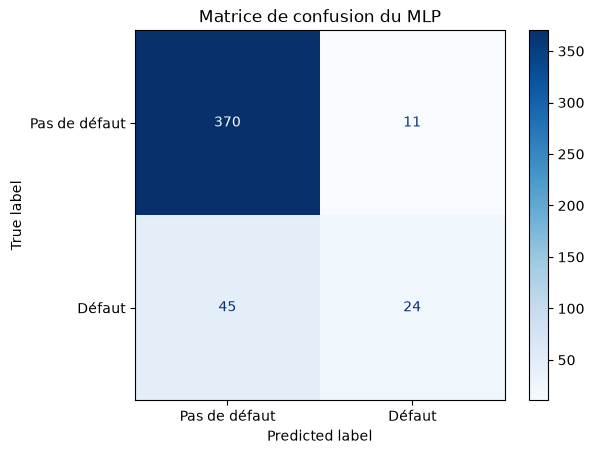

In [32]:
# Phase 5 - Question 3 : Matrice de confusion

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Matrice de confusion :")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pas de défaut", "Défaut"]
)

disp.plot(cmap="Blues")
plt.title("Matrice de confusion du MLP")
plt.show()

La matrice de confusion détaille les bonnes et mauvaises décisions : 370 vrais négatifs, 11 faux positifs, 45 faux négatifs et 24 vrais positifs.

### Phase 5 — Question 3 : Interprétation de la matrice de confusion

La matrice de confusion obtenue sur 450 clients donne :

- **Vrais négatifs (TN) :** 370 clients correctement classés sans défaut.
- **Faux positifs (FP) :** 11 clients classés à risque alors qu'ils ne présentent pas de défaut.
- **Faux négatifs (FN) :** 45 clients à risque non détectés par le modèle.
- **Vrais positifs (TP) :** 24 clients à risque correctement détectés.

Le modèle réalise 394 prédictions correctes sur 450, soit une Accuracy de 87,56 %.

Cependant, il ne détecte que 24 des 69 clients réellement en défaut, soit un Recall d'environ 34,78 %.

**Conclusion :** Malgré une bonne Accuracy globale, le modèle présente une limite importante dans la détection des clients à risque, notamment à cause du nombre élevé de faux négatifs.

In [33]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.89      0.97      0.93       381
           1       0.69      0.35      0.46        69

    accuracy                           0.88       450
   macro avg       0.79      0.66      0.70       450
weighted avg       0.86      0.88      0.86       450



Le rapport affiche la Precision, le Recall et le F1-score. Pour les clients en défaut (classe 1), le Recall est seulement de 35 % environ.

### Phase 5 — Question 5 : Interprétation des résultats

Le modèle obtient une Accuracy globale de 87,56 %, mais son Recall pour la classe 1 est seulement de 34,78 %.

Parmi les 69 clients réellement en défaut de paiement, le modèle détecte correctement 24 clients et ne détecte pas 45 clients (faux négatifs).

**Conclusion :** Le modèle classe correctement la majorité des clients, mais il identifie mal les clients à risque de défaut. Il est nécessaire d'améliorer le Recall pour réduire les faux négatifs.

### Phase 5 — Question 6 : Faux positifs et faux négatifs

**Faux positif (FP) :** Le modèle prédit un défaut de paiement alors que le client ne présente pas de défaut. Dans notre cas, nous avons 11 faux positifs.

**Faux négatif (FN) :** Le modèle prédit une absence de défaut alors que le client est réellement en défaut. Dans notre cas, nous avons 45 faux négatifs.

**Conclusion :** Dans le contexte bancaire, les faux négatifs sont généralement plus dangereux, car la banque risque d'accorder un crédit à un client qui ne pourra pas le rembourser. Il est donc important d'améliorer le Recall pour réduire ces erreurs.

### Phase 5 — Question 7 : Limites de l'Accuracy

Non, l'Accuracy seule n'est pas suffisante lorsque les classes sont déséquilibrées.

Dans notre jeu de test, nous avons 381 clients sans défaut contre seulement 69 clients en défaut.

Le modèle obtient une Accuracy de 87,56 %, mais son Recall pour la classe 1 est seulement de 34,78 %. Il ne détecte donc pas 45 clients réellement en défaut.

**Conclusion :** Une Accuracy élevée peut cacher de mauvaises performances sur la classe minoritaire. Il faut également analyser la Precision, le Recall, le F1-score et la matrice de confusion.

In [34]:
# Phase 5 - Question 8 (Bonus) : AUC et seuils

from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score, recall_score

# Calcul de l'AUC
auc = roc_auc_score(y_test, y_prob.ravel())
print("AUC :", auc)

# Comparaison des seuils
for seuil in [0.2, 0.3, 0.4, 0.5]:
    predictions = (y_prob.ravel() >= seuil).astype(int)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )

    recall = recall_score(
        y_test, predictions, zero_division=0
    )

    print(
        f"Seuil = {seuil} | "
        f"Precision = {precision:.3f} | "
        f"Recall = {recall:.3f}"
    )

AUC : 0.8420251816349043
Seuil = 0.2 | Precision = 0.384 | Recall = 0.768
Seuil = 0.3 | Precision = 0.462 | Recall = 0.623
Seuil = 0.4 | Precision = 0.581 | Recall = 0.522
Seuil = 0.5 | Precision = 0.686 | Recall = 0.348


### Phase 5 — Question 8 (Bonus) : Analyse de l'AUC et des seuils

Le modèle obtient une **AUC de 0,8420**, ce qui indique une bonne capacité à distinguer les clients avec défaut des clients sans défaut.

| Seuil | Precision | Recall |
|---|---|---|
| 0,2 | 38,4 % | 76,8 % |
| 0,3 | 46,2 % | 62,3 % |
| 0,4 | 58,1 % | 52,2 % |
| 0,5 | 68,6 % | 34,8 % |

**Interprétation :** Lorsque le seuil diminue, le Recall augmente mais la Precision diminue. Le modèle détecte davantage de clients en défaut, au prix d'un nombre plus important de faux positifs.

**Conclusion :** Si la priorité de la banque est de détecter un maximum de défauts, le seuil de 0,2 est le plus adapté parmi les seuils testés. Toutefois, le choix final dépend du coût des erreurs de classification.

In [35]:
# Phase 6 - Question 1 : Construction de 3 MLP

import keras

# MLP 1 : 4 -> 8 -> 1
keras.utils.set_random_seed(42)

model1 = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

# MLP 2 : 4 -> 16 -> 1
keras.utils.set_random_seed(42)

model2 = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

# MLP 3 : 4 -> 16 -> 8 -> 1
keras.utils.set_random_seed(42)

model3 = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

print("Les trois architectures sont construites.")

Les trois architectures sont construites.


Nous construisons trois architectures : MLP 1 (8 neurones), MLP 2 (16 neurones) et MLP 3 (16 puis 8 neurones), pour comparer leur performance.

In [36]:
# Phase 6 - Question 2 : MLP 1

# Compilation
model1.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Entraînement
history1 = model1.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=0
)

# Évaluation sur Validation
loss1, acc1 = model1.evaluate(
    X_val, y_val, verbose=0
)

print("Loss validation :", loss1)
print("Accuracy validation :", acc1)

Loss validation : 0.33419471979141235
Accuracy validation : 0.8533333539962769


Nous entraînons MLP 1 pendant 30 époques avec Adam. Sur Validation, il obtient 85,33 % d'Accuracy et une Loss de 0,3342.

In [37]:
# Phase 6 - Question 3 : MLP 2

# Compilation
model2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Entraînement
history2 = model2.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=0
)

# Évaluation sur Validation
loss2, acc2 = model2.evaluate(
    X_val, y_val, verbose=0
)

print("Loss validation MLP 2 :", loss2)
print("Accuracy validation MLP 2 :", acc2)

Loss validation MLP 2 : 0.3328188359737396
Accuracy validation MLP 2 : 0.8577777743339539


Nous entraînons MLP 2, qui possède 16 neurones cachés. Son Accuracy sur Validation atteint 85,78 % et sa Loss est de 0,3328.

In [38]:
# Phase 6 : Entraînement et évaluation du MLP 3

model3.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history3 = model3.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=0
)

loss3, acc3 = model3.evaluate(
    X_val, y_val, verbose=0
)

print("Loss validation MLP 3 :", loss3)
print("Accuracy validation MLP 3 :", acc3)

Loss validation MLP 3 : 0.33457180857658386
Accuracy validation MLP 3 : 0.851111114025116


Nous entraînons MLP 3, avec deux couches cachées. Son Accuracy de Validation est de 85,11 % et sa Loss de 0,3346.

In [39]:
# Phase 6 - Question 4 : Tableau comparatif

import pandas as pd

comparaison = pd.DataFrame({
    "Architecture": [
        "MLP 1 (8)",
        "MLP 2 (16)",
        "MLP 3 (16, 8)"
    ],
    "Loss validation": [loss1, loss2, loss3],
    "Accuracy validation": [acc1, acc2, acc3]
})

display(comparaison)

,Architecture,Loss validation,Accuracy validation
0,MLP 1 (8),0.334195,0.853333
1,MLP 2 (16),0.332819,0.857778
2,"MLP 3 (16, 8)",0.334572,0.851111


Nous réunissons les résultats des trois architectures dans un tableau. MLP 2 a la meilleure Accuracy et la plus faible Loss sur Validation.

### Phase 6 — Question 5 : Influence du nombre de neurones

Non, l'augmentation du nombre de neurones n'améliore pas systématiquement les performances.

Le MLP 2, avec 16 neurones, obtient une meilleure Accuracy de validation (85,78 %) que le MLP 1, avec 8 neurones (85,33 %).

Cependant, le MLP 3, qui possède une couche cachée supplémentaire, présente une Accuracy plus faible (85,11 %).

**Conclusion :** L'augmentation de la complexité du réseau ne garantit pas une amélioration des performances.

### Phase 6 — Question 6 : Choix de la meilleure architecture

Le MLP 2, composé d'une couche cachée de 16 neurones, donne les meilleurs résultats sur les données de validation.

Il obtient une Accuracy de **85,78 %** et une Loss de **0,3328**, ce qui correspond à la meilleure performance parmi les trois architectures testées.

**Conclusion :** Nous sélectionnons le MLP 2 comme meilleur modèle pour l'évaluation finale sur les données de test.

In [40]:
# Phase 6 - Question 7 : Évaluation sur Test

# Évaluation du meilleur modèle (MLP 2)
loss_test2, acc_test2 = model2.evaluate(
    X_test, y_test,
    verbose=0
)

# Comparaison avec Validation
print("Meilleur modèle : MLP 2")
print("Loss Validation :", loss2)
print("Accuracy Validation :", acc2)

print("Loss Test :", loss_test2)
print("Accuracy Test :", acc_test2)

Meilleur modèle : MLP 2
Loss Validation : 0.3328188359737396
Accuracy Validation : 0.8577777743339539
Loss Test : 0.3219658136367798
Accuracy Test : 0.8733333349227905


Nous testons le modèle choisi, MLP 2, sur des données non utilisées pour sa sélection. Son Accuracy passe de 85,78 % sur Validation à 87,33 % sur Test.

### Phase 6 — Question 8 : Conclusion

Les résultats montrent que l'augmentation du nombre de neurones peut améliorer légèrement les performances d'un réseau MLP, mais cette amélioration n'est pas systématique.

Dans notre expérience, le MLP 2 (16 neurones) obtient une meilleure Accuracy de validation (85,78 %) que le MLP 1 (8 neurones : 85,33 %).

Cependant, l'ajout d'une deuxième couche cachée dans le MLP 3 n'améliore pas les résultats, puisque son Accuracy de validation est de 85,11 %.

Nous concluons qu'un réseau plus complexe n'est pas nécessairement plus performant. Le choix de la meilleure architecture doit être effectué sur les données de validation, tandis que les données de test servent uniquement à évaluer ses performances finales sur des observations non utilisées pour la sélection.